# The big questions (step 0.37)

Step 0.36 asked which *situations* matter. This notebook asks about *team quality*: what kind of strength goes with winning, and what carries over to next season.

1. Does yard differential predict wins?
2. Is offensive or defensive EPA more predictive of win %?
3. Which is more stable from one season to the next?

**Data.** One row per team per regular season, 2016–2025 (the play-by-play years): 32 teams × 10 seasons = 320 team-seasons.
- The totals come from `mart_team_splits`, the mart the site will read. Its `venue` rows cover every game, so summing them gives each team's whole season.
- 2020 is included: the 2020 rule only applies to home/away comparisons.

**One caveat about EPA, from step 0.36.** EPA is measured against an expected-points model that already allows for home field, the roof and the era. Over a whole season every team plays about half its games at home, so this hardly matters for season totals.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import Markdown, display
from matplotlib.ticker import PercentFormatter

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(ROOT))

from pipeline.analysis import (
    EPA_FIRST_SEASON,
    FIGURES_DIR,
    LAST_SEASON,
    N_RESAMPLES,
    SEED,
    SERIES,
    SURFACE,
    TEXT_SECONDARY,
    chart_style,
    read_mart,
    regular_season,
    save_figure,
)

chart_style()
pd.set_option("display.width", 200)

## The statistics, in plain English

**Correlation (r).** A number from −1 to +1 for how tightly two measures move together along a straight line.
- +1: they rise in lockstep.
- 0: no straight-line relationship.
- Negative: one falls as the other rises.

It says nothing about cause, only about moving together.

**Simple regression.** The straight line that best predicts one measure from another, chosen to make the squared misses as small as possible.
- Its **slope** is the answer in real units: "each extra 10 yards per game of differential goes with X more points of win %".
- Its **intercept** is the prediction when the other measure is zero.
- `statsmodels` also gives the slope a 95% CI. That interval comes from a formula that treats every team-season as independent, which is only roughly true (see the caveats).

**R² (R-squared).** The share of the ups and downs in win % that the line accounts for, from 0 to 1. With one predictor it is simply r². With two (offense and defense together), R² can't go down when the second is added, so the interesting question is how much it rises.

**Bootstrap by franchise.** As in step 0.36, resample and recompute, here 2,000 times. This time the unit drawn is a whole franchise with all 10 of its seasons, so a team's consecutive seasons stay together. The 95% interval is the middle 95% of the 2,000 answers (a *percentile interval*), which suits correlations: they can't pass ±1, so their wobble isn't symmetric. A difference whose interval excludes zero is one that another draw of franchises wouldn't reverse.

In [2]:
splits = read_mart(
    "mart_team_splits",
    "situation_key = 'venue' AND season_type = 'REG' AND season BETWEEN :first AND :last",
    {"first": EPA_FIRST_SEASON, "last": LAST_SEASON},
)
team_seasons = splits.groupby(["team", "season"], as_index=False).sum(numeric_only=True)
team_seasons["win_pct"] = (team_seasons["wins"] + team_seasons["ties"] / 2) / team_seasons["games"]
team_seasons["point_diff"] = (team_seasons["points_for"] - team_seasons["points_against"]) / team_seasons["games"]
team_seasons["yard_diff"] = (team_seasons["yards"] - team_seasons["def_yards"]) / team_seasons["stats_games"]
team_seasons["off_epa_play"] = team_seasons["epa"] / (team_seasons["dropbacks"] + team_seasons["rushes"])
team_seasons["def_epa_play"] = team_seasons["def_epa"] / (team_seasons["def_dropbacks"] + team_seasons["def_rushes"])

# The venue rows add up to every game: check against team_games.
team_games = regular_season(read_mart("team_games"), EPA_FIRST_SEASON, LAST_SEASON)
assert len(team_seasons) == team_games.groupby(["team", "season"]).ngroups == 320
assert team_seasons["games"].sum() == len(team_games)
assert (team_seasons["stats_games"] == team_seasons["games"]).all()  # every game since 2016 has play-by-play

# Pairs of consecutive seasons for the same franchise: 2016→2017 through 2024→2025.
following = team_seasons[["team", "season", "win_pct", "yard_diff", "point_diff", "off_epa_play", "def_epa_play"]].assign(
    season=lambda d: d["season"] - 1
)
pairs = team_seasons.merge(following, on=["team", "season"], suffixes=("", "_next"))
assert len(pairs) == 32 * 9

print(f"{len(team_seasons)} team-seasons ({team_seasons['games'].sum():,} team-games), {len(pairs)} pairs of consecutive seasons")
team_seasons[["win_pct", "point_diff", "yard_diff", "off_epa_play", "def_epa_play"]].describe().round(3)

320 team-seasons (5,278 team-games), 288 pairs of consecutive seasons


,win_pct,point_diff,yard_diff,off_epa_play,def_epa_play
count,320.000,320.000,320.000,320.000,320.000
mean,0.500,0.003,0.019,0.005,0.005
std,0.191,6.032,46.875,0.087,0.068
min,0.000,-13.375,-117.250,-0.240,-0.217
25%,0.353,-4.239,-28.537,-0.055,-0.041
50%,0.500,-0.088,0.344,0.009,0.010
75%,0.647,4.507,30.119,0.064,0.049
max,0.882,15.562,109.176,0.237,0.205


`franchise_bootstrap` runs a statistic on 2,000 resamples of franchises. `percentile_interval` takes the middle 95%.

In [3]:
def corr(frame: pd.DataFrame, x: str, y: str) -> float:
    return float(np.corrcoef(frame[x], frame[y])[0, 1])


def franchise_bootstrap(frame: pd.DataFrame, statistic, n_resamples: int = N_RESAMPLES, seed: int = SEED) -> np.ndarray:
    """statistic(frame) on resamples of whole franchises, drawn with replacement; each keeps all its rows."""
    rng = np.random.default_rng(seed)
    rows_of = {team: np.flatnonzero(frame["team"].to_numpy() == team) for team in frame["team"].unique()}
    teams = list(rows_of)
    return np.array(
        [statistic(frame.iloc[np.concatenate([rows_of[t] for t in rng.choice(teams, len(teams))])]) for _ in range(n_resamples)]
    )


def percentile_interval(samples: np.ndarray) -> tuple:
    low, high = np.percentile(samples, [2.5, 97.5], axis=0)
    return low, high


def fmt(estimate: float, low: float, high: float, digits: int = 2) -> str:
    return f"{estimate:+.{digits}f} [{low:+.{digits}f}, {high:+.{digits}f}]"

## 1. Does yard differential predict wins?

**Yard differential** is yards gained minus yards allowed, per game. There are two versions of the question:
- **The same season:** do teams that out-gain opponents win more?
- **The next season:** is this year's yard differential a guide to next year's win %? Here it is compared with this year's point differential and win %.

In [4]:
yards_fit = smf.ols("win_pct ~ yard_diff", data=team_seasons).fit()
slope = yards_fit.params["yard_diff"]
slope_low, slope_high = yards_fit.conf_int().loc["yard_diff"]
yards_r = corr(team_seasons, "yard_diff", "win_pct")
yards_r_low, yards_r_high = percentile_interval(franchise_bootstrap(team_seasons, lambda d: corr(d, "yard_diff", "win_pct")))
points_r = corr(team_seasons, "point_diff", "win_pct")

print(f"win % = {yards_fit.params['Intercept']:.3f} + {slope:.5f} × yard differential per game  (n = {int(yards_fit.nobs)})")
print(f"r = {fmt(yards_r, yards_r_low, yards_r_high)}, R² = {yards_fit.rsquared:.2f}")
print(
    f"10 more yards per game of differential: {1000 * slope:+.1f} points of win % [{1000 * slope_low:+.1f}, {1000 * slope_high:+.1f}], "
    f"about {170 * slope:.2f} wins over a 17-game season"
)
print(f"For comparison, point differential: r = {points_r:.2f}, R² = {points_r ** 2:.2f}")

win % = 0.500 + 0.00286 × yard differential per game  (n = 320)
r = +0.70 [+0.64, +0.75], R² = 0.49
10 more yards per game of differential: +2.9 points of win % [+2.5, +3.2], about 0.49 wins over a 17-game season
For comparison, point differential: r = 0.90, R² = 0.80


The teams furthest from the line won far more, or far fewer, games than their yards suggest. Close games, turnovers and special teams decide records that yards don't.

In [5]:
team_seasons["yards_residual"] = yards_fit.resid
outliers = team_seasons.sort_values("yards_residual").iloc[[0, 1, 2, -3, -2, -1]]
outliers[["team", "season", "wins", "losses", "ties", "yard_diff", "point_diff", "yards_residual"]].round(2)

,team,season,wins,losses,ties,yard_diff,point_diff,yards_residual
71,CLE,2017,0,16,0,-19.25,-11.00,-0.44
140,JAX,2016,3,13,0,13.25,-5.12,-0.35
173,LAC,2019,5,11,0,54.38,-0.50,-0.34
113,GB,2019,13,3,0,-7.12,3.94,0.33
206,MIN,2022,13,4,0,-27.24,-0.18,0.34
158,KC,2024,15,2,0,7.00,3.47,0.36


### Next season

Each predictor this season is set against win % next season, for the 288 pairs of consecutive seasons.

In [6]:
PREDICTORS = {
    "yard_diff": "Yard differential",
    "point_diff": "Point differential",
    "win_pct": "Win %",
    "off_epa_play": "Offensive EPA/play",
    "def_epa_play": "Defensive EPA/play allowed",
}
next_r = {name: corr(pairs, name, "win_pct_next") for name in PREDICTORS}
next_boot = franchise_bootstrap(pairs, lambda d: [corr(d, name, "win_pct_next") for name in PREDICTORS])
next_low, next_high = percentile_interval(next_boot)
next_table = pd.DataFrame(
    {"r with next season's win %": next_r.values(), "95% CI low": next_low, "95% CI high": next_high, "R²": np.square(list(next_r.values()))},
    index=PREDICTORS.values(),
).round(3)
display(next_table)

column = {name: i for i, name in enumerate(PREDICTORS)}
differences = {
    "point differential − yard differential": next_boot[:, column["point_diff"]] - next_boot[:, column["yard_diff"]],
    "point differential − win %": next_boot[:, column["point_diff"]] - next_boot[:, column["win_pct"]],
    "yard differential − win %": next_boot[:, column["yard_diff"]] - next_boot[:, column["win_pct"]],
}
point_minus_yard = next_r["point_diff"] - next_r["yard_diff"]
point_minus_win = next_r["point_diff"] - next_r["win_pct"]
for label, samples in differences.items():
    low, high = percentile_interval(samples)
    print(f"r({label}): 95% CI [{low:+.3f}, {high:+.3f}]")

,r with next season's win %,95% CI low,95% CI high,R²
Yard differential,0.332,0.227,0.423,0.110
Point differential,0.402,0.293,0.495,0.162
Win %,0.369,0.264,0.456,0.136
Offensive EPA/play,0.366,0.244,0.465,0.134
Defensive EPA/play allowed,-0.178,-0.285,-0.068,0.032


r(point differential − yard differential): 95% CI [+0.008, +0.129]
r(point differential − win %): 95% CI [-0.009, +0.078]
r(yard differential − win %): 95% CI [-0.114, +0.037]


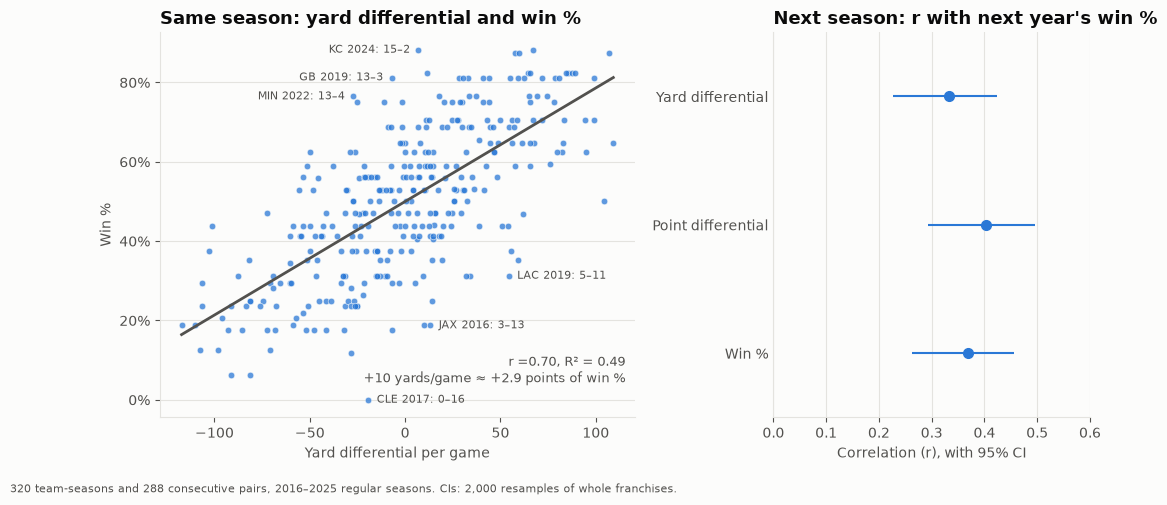

In [7]:
fig, (ax_fit, ax_next) = plt.subplots(1, 2, figsize=(12, 5), gridspec_kw={"width_ratios": [3, 2], "wspace": 0.35})

ax_fit.scatter(team_seasons["yard_diff"], team_seasons["win_pct"], s=22, color=SERIES[0], alpha=0.75, edgecolor=SURFACE, linewidth=0.5)
xs = np.linspace(team_seasons["yard_diff"].min(), team_seasons["yard_diff"].max(), 50)
ax_fit.plot(xs, yards_fit.params["Intercept"] + slope * xs, color=TEXT_SECONDARY, linewidth=2)
for _, row in outliers.iterrows():
    record = f"{row['wins']:.0f}–{row['losses']:.0f}" + (f"–{row['ties']:.0f}" if row["ties"] else "")
    above = row["yards_residual"] > 0  # over-achievers sit above the dense middle: label them on the left
    ax_fit.annotate(f"{row['team']} {row['season']:.0f}: {record}", (row["yard_diff"], row["win_pct"]), xytext=(-6 if above else 6, 0),
                    textcoords="offset points", ha="right" if above else "left", va="center", fontsize=8, color=TEXT_SECONDARY)
ax_fit.text(0.98, 0.08, f"r ={yards_r:.2f}, R² = {yards_fit.rsquared:.2f}\n+10 yards/game ≈ {1000 * slope:+.1f} points of win %",
            transform=ax_fit.transAxes, ha="right", va="bottom", fontsize=9, color=TEXT_SECONDARY)
ax_fit.set_title("Same season: yard differential and win %")
ax_fit.set_xlabel("Yard differential per game")
ax_fit.set_ylabel("Win %")
ax_fit.yaxis.set_major_formatter(PercentFormatter(1.0))

order = ["yard_diff", "point_diff", "win_pct"]
for y, name in enumerate(order):
    i = column[name]
    ax_next.errorbar(next_r[name], y, xerr=[[next_r[name] - next_low[i]], [next_high[i] - next_r[name]]], fmt="o", color=SERIES[0],
                     markersize=7, elinewidth=1.5, capsize=0)
ax_next.set_yticks(range(len(order)), [PREDICTORS[name] for name in order])
ax_next.set_ylim(len(order) - 0.5, -0.5)
ax_next.set_xlim(0, 0.6)
ax_next.grid(axis="x", visible=True)
ax_next.grid(axis="y", visible=False)
ax_next.tick_params(axis="y", length=0)
ax_next.set_title("Next season: r with next year's win %")
ax_next.set_xlabel("Correlation (r), with 95% CI")

fig.text(0.0, -0.04, f"{len(team_seasons)} team-seasons and {len(pairs)} consecutive pairs, {EPA_FIRST_SEASON}–{LAST_SEASON} regular seasons. "
         "CIs: 2,000 resamples of whole franchises.", fontsize=8, color=TEXT_SECONDARY)
save_figure(fig, "yards_vs_wins")
plt.show()

In [8]:
point_yard_low, _ = percentile_interval(differences["point differential − yard differential"])
point_win_low, point_win_high = percentile_interval(differences["point differential − win %"])
assert yards_r > 0.6 and point_yard_low > 0 and point_win_low < 0 < point_win_high  # the claims below
display(Markdown(
    f"**Answer.** Yes within a season, less so for the next one. "
    f"In the same season, teams that out-gain their opponents win more: r = {yards_r:.2f}, so yard differential accounts for "
    f"{yards_fit.rsquared:.0%} of the variation in win %. Each extra 10 yards per game of differential goes with about "
    f"{1000 * slope:.1f} points of win %, about {170 * slope:.1f} of a win over a 17-game season. Point differential tracks wins "
    f"much more closely (r = {points_r:.2f}), because points also capture red-zone finishing, turnovers and special teams, which yards miss. "
    f"As a guide to *next* season, yard differential is weaker than point differential (r = {next_r['yard_diff']:.2f} against "
    f"{next_r['point_diff']:.2f}; the bootstrap interval for the gap excludes zero), and point differential can't be told apart from "
    f"this season's win % ({next_r['win_pct']:.2f}). All three explain under a fifth of next season's win %: most of a record doesn't carry over."
))

**Answer.** Yes within a season, less so for the next one. In the same season, teams that out-gain their opponents win more: r = 0.70, so yard differential accounts for 49% of the variation in win %. Each extra 10 yards per game of differential goes with about 2.9 points of win %, about 0.5 of a win over a 17-game season. Point differential tracks wins much more closely (r = 0.90), because points also capture red-zone finishing, turnovers and special teams, which yards miss. As a guide to *next* season, yard differential is weaker than point differential (r = 0.33 against 0.40; the bootstrap interval for the gap excludes zero), and point differential can't be told apart from this season's win % (0.37). All three explain under a fifth of next season's win %: most of a record doesn't carry over.

## 2. Is offensive or defensive EPA more predictive of win %?

- **Offensive EPA/play:** the points the offense adds per play beyond what the down, distance and field position expected.
- **Defensive EPA/play allowed:** the same for the opponents' offense. Lower is better.

Three regressions answer the question: win % on offense alone, on defense alone, and on both together.

In [9]:
fits = {
    "offense alone": smf.ols("win_pct ~ off_epa_play", data=team_seasons).fit(),
    "defense alone": smf.ols("win_pct ~ def_epa_play", data=team_seasons).fit(),
    "both together": smf.ols("win_pct ~ off_epa_play + def_epa_play", data=team_seasons).fit(),
}
fit_table = pd.DataFrame(
    {
        "R²": {name: fit.rsquared for name, fit in fits.items()},
        "offense slope": {name: fit.params.get("off_epa_play", np.nan) for name, fit in fits.items()},
        "defense slope": {name: fit.params.get("def_epa_play", np.nan) for name, fit in fits.items()},
    }
).round(3)
display(fit_table)

off_def_r = corr(team_seasons, "off_epa_play", "def_epa_play")
off_sd, def_sd = team_seasons["off_epa_play"].std(), team_seasons["def_epa_play"].std()
r2_boot = franchise_bootstrap(
    team_seasons, lambda d: corr(d, "off_epa_play", "win_pct") ** 2 - corr(d, "def_epa_play", "win_pct") ** 2
)
r2_gap = fits["offense alone"].rsquared - fits["defense alone"].rsquared
r2_gap_low, r2_gap_high = percentile_interval(r2_boot)
next_gap = next_boot[:, column["off_epa_play"]] + next_boot[:, column["def_epa_play"]]  # |offense r| − |defense r|; defense's r is negative
next_gap_low, next_gap_high = percentile_interval(next_gap)

print(f"R² offense − R² defense: {fmt(r2_gap, r2_gap_low, r2_gap_high)}")
print(f"Offense and defense across team-seasons: r = {off_def_r:+.3f}")
print(f"Spread across team-seasons (SD): offense {off_sd:.3f}, defense {def_sd:.3f} EPA/play")
print(f"Next season's win %: offense r = {next_r['off_epa_play']:+.2f}, defense r = {next_r['def_epa_play']:+.2f}; "
      f"|offense| − |defense| 95% CI [{next_gap_low:+.3f}, {next_gap_high:+.3f}]")

,R²,offense slope,defense slope
offense alone,0.501,1.557,NaN
defense alone,0.267,NaN,-1.451
both together,0.756,1.538,-1.417


R² offense − R² defense: +0.23 [+0.11, +0.35]
Offense and defense across team-seasons: r = -0.017
Spread across team-seasons (SD): offense 0.087, defense 0.068 EPA/play
Next season's win %: offense r = +0.37, defense r = -0.18; |offense| − |defense| 95% CI [-0.001, +0.362]


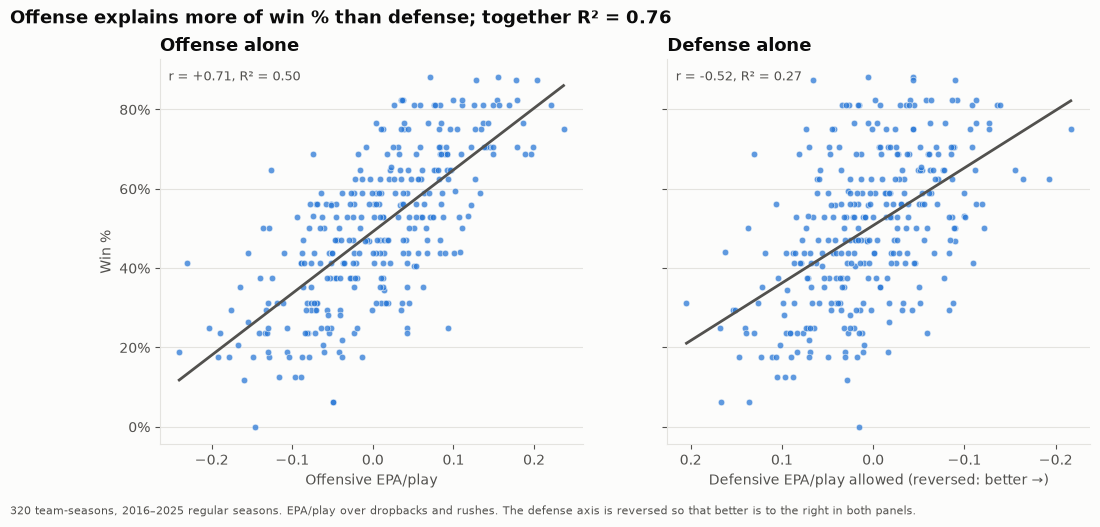

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)
panels = [
    ("off_epa_play", "offense alone", "Offensive EPA/play", False),
    ("def_epa_play", "defense alone", "Defensive EPA/play allowed (reversed: better →)", True),
]
for ax, (column_name, fit_name, xlabel, reverse) in zip(axes, panels):
    fit = fits[fit_name]
    ax.scatter(team_seasons[column_name], team_seasons["win_pct"], s=22, color=SERIES[0], alpha=0.75, edgecolor=SURFACE, linewidth=0.5)
    xs = np.linspace(team_seasons[column_name].min(), team_seasons[column_name].max(), 50)
    ax.plot(xs, fit.params["Intercept"] + fit.params[column_name] * xs, color=TEXT_SECONDARY, linewidth=2)
    r_value = corr(team_seasons, column_name, "win_pct")
    ax.text(0.02, 0.97, f"r = {r_value:+.2f}, R² = {fit.rsquared:.2f}", transform=ax.transAxes, va="top", fontsize=9, color=TEXT_SECONDARY)
    if reverse:
        ax.invert_xaxis()
    ax.set_xlabel(xlabel)
    ax.set_title(fit_name.capitalize())
axes[0].set_ylabel("Win %")
axes[0].yaxis.set_major_formatter(PercentFormatter(1.0))
fig.suptitle(f"Offense explains more of win % than defense; together R² = {fits['both together'].rsquared:.2f}",
             x=0.0, ha="left", fontsize=13, fontweight="bold")
fig.text(0.0, -0.03, f"{len(team_seasons)} team-seasons, {EPA_FIRST_SEASON}–{LAST_SEASON} regular seasons. EPA/play over dropbacks and rushes. "
         "The defense axis is reversed so that better is to the right in both panels.", fontsize=8, color=TEXT_SECONDARY)
save_figure(fig, "epa_off_vs_def")
plt.show()

In [11]:
both = fits["both together"]
assert r2_gap_low > 0 and abs(off_def_r) < 0.1 and off_sd > def_sd and abs(next_gap_low) < 0.05  # the claims below
next_gap_side = "only just clears" if next_gap_low > 0 else "just touches"
display(Markdown(
    f"**Answer.** Offense. Offensive EPA/play accounts for {fits['offense alone'].rsquared:.0%} of the variation in win %, "
    f"defensive EPA/play allowed for {fits['defense alone'].rsquared:.0%}; the bootstrap interval for the gap is "
    f"{r2_gap_low:.0%} to {r2_gap_high:.0%} of R², clear of zero. A unit of EPA/play is worth about the same on either side of the ball "
    f"(fitted together: {10 * both.params['off_epa_play']:.0f} points of win % for every 0.1 EPA/play better on offense, "
    f"{10 * abs(both.params['def_epa_play']):.0f} on defense). "
    f"Offense matters more because teams differ more on offense (SD {off_sd:.3f} against {def_sd:.3f}). "
    f"A team's offense and defense are almost unrelated (r = {off_def_r:+.2f}), so together they account for "
    f"{both.rsquared:.0%}, nearly the sum of the two. Offense is also the better guide to next season's win % "
    f"(r = {next_r['off_epa_play']:.2f} against {next_r['def_epa_play']:.2f}), but the interval for that gap "
    f"({next_gap_low:+.2f} to {next_gap_high:+.2f}) {next_gap_side} zero, so that part is suggestive rather than settled."
))

**Answer.** Offense. Offensive EPA/play accounts for 50% of the variation in win %, defensive EPA/play allowed for 27%; the bootstrap interval for the gap is 11% to 35% of R², clear of zero. A unit of EPA/play is worth about the same on either side of the ball (fitted together: 15 points of win % for every 0.1 EPA/play better on offense, 14 on defense). Offense matters more because teams differ more on offense (SD 0.087 against 0.068). A team's offense and defense are almost unrelated (r = -0.02), so together they account for 76%, nearly the sum of the two. Offense is also the better guide to next season's win % (r = 0.37 against -0.18), but the interval for that gap (-0.00 to +0.36) just touches zero, so that part is suggestive rather than settled.

## 3. Which is more stable from one season to the next?

For each franchise, this season's offensive (and defensive) EPA/play is correlated with next season's. A high correlation means the unit stays good or bad; a low one means last year is a weak guide.

In the chart, the dashed line is perfect persistence (next season = this season). The fitted line is flatter: good units get worse and bad ones better on average. Step 0.38 returns to this as regression to the mean.

In [12]:
STABILITY = {
    "off_epa_play": "Offensive EPA/play",
    "def_epa_play": "Defensive EPA/play allowed",
    "yard_diff": "Yard differential",
    "point_diff": "Point differential",
}
stability_r = {name: corr(pairs, name, f"{name}_next") for name in STABILITY}
stability_boot = franchise_bootstrap(pairs, lambda d: [corr(d, name, f"{name}_next") for name in STABILITY])
stability_low, stability_high = percentile_interval(stability_boot)
display(pd.DataFrame({"r, season to next": stability_r.values(), "95% CI low": stability_low, "95% CI high": stability_high},
                     index=STABILITY.values()).round(3))
stability_gap_low, stability_gap_high = percentile_interval(stability_boot[:, 0] - stability_boot[:, 1])
print(f"r offense − r defense: {fmt(stability_r['off_epa_play'] - stability_r['def_epa_play'], stability_gap_low, stability_gap_high, 3)}")

,"r, season to next",95% CI low,95% CI high
Offensive EPA/play,0.390,0.269,0.482
Defensive EPA/play allowed,0.263,0.160,0.358
Yard differential,0.376,0.254,0.472
Point differential,0.408,0.288,0.511


r offense − r defense: +0.127 [-0.032, +0.274]


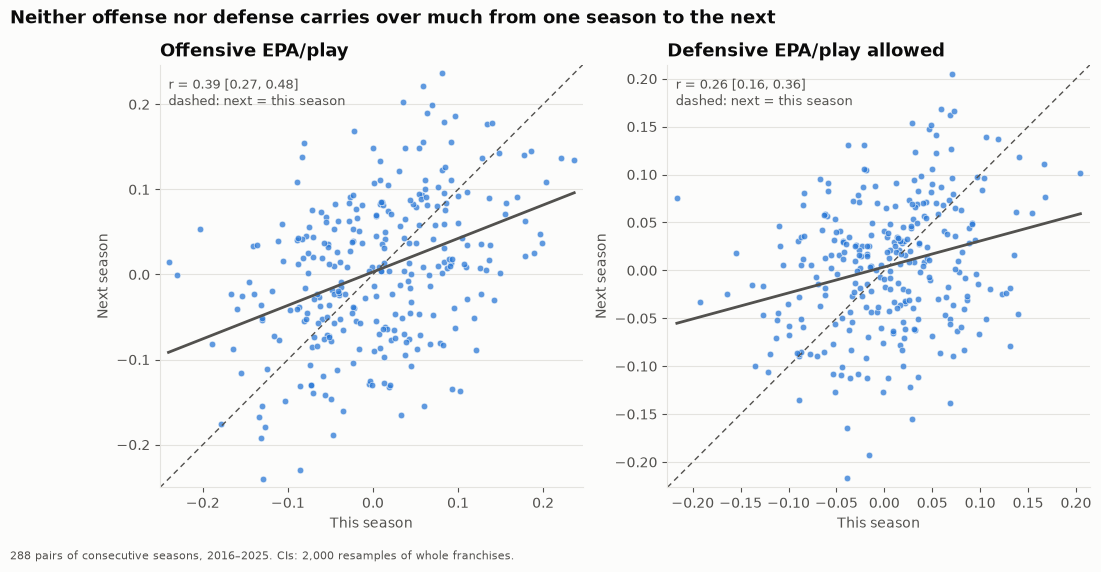

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
for i, (ax, name) in enumerate(zip(axes, ["off_epa_play", "def_epa_play"])):
    x, y = pairs[name], pairs[f"{name}_next"]
    low_lim, high_lim = min(x.min(), y.min()) - 0.01, max(x.max(), y.max()) + 0.01
    ax.plot([low_lim, high_lim], [low_lim, high_lim], color=TEXT_SECONDARY, linewidth=1, linestyle=(0, (4, 3)))
    ax.scatter(x, y, s=22, color=SERIES[0], alpha=0.75, edgecolor=SURFACE, linewidth=0.5)
    slope_next, intercept_next = np.polyfit(x, y, 1)
    xs = np.linspace(x.min(), x.max(), 50)
    ax.plot(xs, intercept_next + slope_next * xs, color=TEXT_SECONDARY, linewidth=2)
    ax.text(0.02, 0.97, f"r = {stability_r[name]:.2f} [{stability_low[i]:.2f}, {stability_high[i]:.2f}]\ndashed: next = this season",
            transform=ax.transAxes, va="top", fontsize=9, color=TEXT_SECONDARY)
    ax.set_xlim(low_lim, high_lim)
    ax.set_ylim(low_lim, high_lim)
    ax.set_aspect("equal")
    ax.set_title(STABILITY[name])
    ax.set_xlabel("This season")
    ax.set_ylabel("Next season")
fig.suptitle("Neither offense nor defense carries over much from one season to the next", x=0.0, ha="left", fontsize=13, fontweight="bold")
fig.text(0.0, -0.02, f"{len(pairs)} pairs of consecutive seasons, {EPA_FIRST_SEASON}–{LAST_SEASON}. CIs: 2,000 resamples of whole franchises.",
         fontsize=8, color=TEXT_SECONDARY)
save_figure(fig, "epa_stability")
plt.show()

In [14]:
assert stability_r["off_epa_play"] > stability_r["def_epa_play"] and stability_gap_low < 0 < stability_gap_high  # the claims below
display(Markdown(
    f"**Answer.** Offense looks more stable, but not provably so. This season's offensive EPA/play correlates "
    f"{stability_r['off_epa_play']:.2f} with next season's, defensive {stability_r['def_epa_play']:.2f}. With ten seasons of data the "
    f"bootstrap interval for the gap ({stability_gap_low:+.2f} to {stability_gap_high:+.2f}) includes zero, so equal stability can't be "
    f"ruled out. Both are modest: a correlation of about {stability_r['off_epa_play']:.1f} means only about "
    f"{stability_r['off_epa_play'] ** 2:.0%} of next season's offensive EPA is foreseen by this season's. Yard and point differential carry "
    f"over about as much ({stability_r['yard_diff']:.2f} and {stability_r['point_diff']:.2f}). Together with question 2: offense clearly "
    f"matters more for winning, and it may also carry over a little better, but ten seasons can't show the second part."
))

**Answer.** Offense looks more stable, but not provably so. This season's offensive EPA/play correlates 0.39 with next season's, defensive 0.26. With ten seasons of data the bootstrap interval for the gap (-0.03 to +0.27) includes zero, so equal stability can't be ruled out. Both are modest: a correlation of about 0.4 means only about 15% of next season's offensive EPA is foreseen by this season's. Yard and point differential carry over about as much (0.38 and 0.41). Together with question 2: offense clearly matters more for winning, and it may also carry over a little better, but ten seasons can't show the second part.

## Caveats

- **Team-seasons aren't fully independent.** Teams in the same season play each other: one team's yards gained are another's allowed. The franchise bootstrap keeps each team's seasons together, but not the links between opponents. The intervals are therefore somewhat optimistic, as are `statsmodels`' formula intervals for the slopes.
- **Ten seasons.** Play-by-play starts in 2016, so the EPA and yard questions rest on 320 team-seasons and 288 pairs. Small gaps, like offense against defense in stability, can't be settled.
- **Correlation isn't cause.** Out-gaining opponents goes with winning, but a team that leads late runs the ball and gives up yards. The direction runs both ways.
- **EPA's built-in adjustments.** EPA already allows for home field, the roof and the era (step 0.36). Season totals balance home and away games, so this matters little here.

## Done-when check

Each question has a one-paragraph answer (above) and a chart.

In [15]:
for name in ["yards_vs_wins", "epa_off_vs_def", "epa_stability"]:
    assert (FIGURES_DIR / f"{name}.png").exists(), name
assert len(team_seasons) == 320 and len(pairs) == 288
print("3 questions answered, 3 charts saved: yards_vs_wins.png, epa_off_vs_def.png, epa_stability.png")

3 questions answered, 3 charts saved: yards_vs_wins.png, epa_off_vs_def.png, epa_stability.png
